In [2]:
import numpy as np
from openfermion import FermionOperator, QubitOperator, jordan_wigner

In [3]:
# H2 molecule
from pyscf import gto, scf

# Build molecule
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 0.74)]],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.11675930739643


np.float64(-1.1167593073964255)

In [4]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
print(e_nuc)

[[-1.25330979e+00  3.71049551e-17]
 [ 1.34841040e-17 -4.75068849e-01]]
[[[[ 6.74755927e-01 -3.75785642e-17]
   [-5.45047948e-17  1.81210462e-01]]

  [[-5.45047948e-17  1.81210462e-01]
   [ 6.63711401e-01  4.06319362e-16]]]


 [[[-3.75785642e-17  6.63711401e-01]
   [ 1.81210462e-01  5.57982113e-16]]

  [[ 1.81210462e-01  5.57982113e-16]
   [ 4.06319362e-16  6.97651504e-01]]]]
0.7151043390810812


In [5]:
from openfermion import InteractionOperator
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5*eri_so)

In [6]:
from openfermion import get_sparse_operator

H_sparse = get_sparse_operator(hamiltonian)
np.linalg.eigvals(H_sparse.toarray().real)


array([-0.53077336, -0.16835243, -1.13728383,  0.48314267,  0.71510434,
        0.24003549,  0.24003549, -0.53820545, -0.53077336,  0.3555207 ,
       -0.53820545, -0.53077336,  0.3555207 , -0.44561582, -0.44561582,
        0.92317918])

In [7]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
energy, ci = cisolver.kernel()
print("FCI energy:", energy)

FCI energy: -1.137283834488502


Ansatz Hardware efficient

Givens rotation

In [8]:
def add_parity_gates(qc, i, j):

    def parity_string_qubits(p, q):
        lo, hi = min(p, q), max(p, q)
        return list(range(lo + 1, hi))

    parity_qubits = parity_string_qubits(i, j)

    for r in parity_qubits:
        qc.cz(r, j)


In [9]:
def add_givens_rotation(qc, i, j, theta):

    add_parity_gates(qc, i, j)

    qc.cx(i, j)
    qc.cry(-2*theta, j, i)
    qc.cx(i, j)

    add_parity_gates(qc, i, j)

In [10]:
def add_entanglement_gate(qc, i, j, theta):
    qc.crz(theta, i, j)

\begin{aligned}
U =
\begin{pmatrix}
1&0&0&0\\
0&\cos\theta&\sin\theta&0\\
0&-\sin\theta&\cos\theta&0\\
0&0&0&1
\end{pmatrix}
\end{aligned}

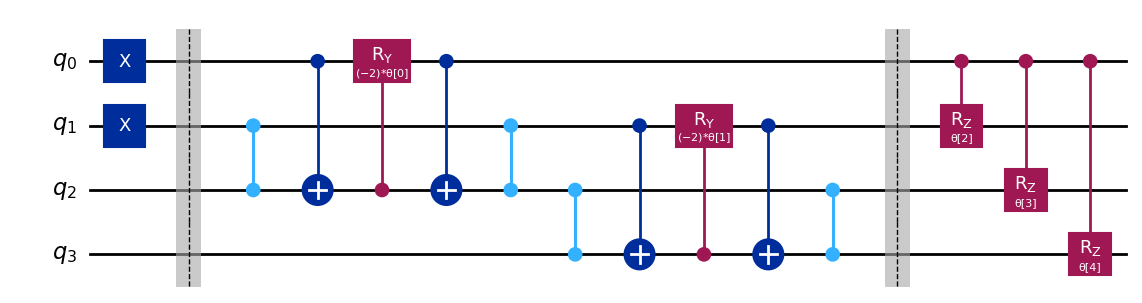

In [11]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import XXPlusYYGate



# Define the variational parameters
theta_vector = ParameterVector("θ", 5)

# Build the ansatz
qc = QuantumCircuit(4)

# reference
qc.x(0)
qc.x(1)
qc.barrier()

# givens
add_givens_rotation(qc, 0, 2, theta=theta_vector[0])
add_givens_rotation(qc, 1, 3, theta=theta_vector[1])

qc.barrier()

# entanglement
add_entanglement_gate(qc, 0, 1, theta=theta_vector[2])
add_entanglement_gate(qc, 0, 2, theta=theta_vector[3])
add_entanglement_gate(qc, 0, 3, theta=theta_vector[4])


qc.draw('mpl')

In [12]:
from qiskit.primitives import StatevectorSampler
def cost_function(params, H_qubit):
    energy = 0.0
    for op, coeff in H_qubit.terms.items():

        qc_bound = qc.assign_parameters(params)

        qc_meas = qc_bound.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=100000).result()
        counts = result[0].data.meas.get_counts()
        # print(counts)

        shots = sum(counts.values())

        for bitstring, count in counts.items():

            parity = 1

            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

In [13]:
from openfermion import jordan_wigner
H_qubit = jordan_wigner(hamiltonian)

In [14]:
import numpy as np
from scipy.optimize import minimize

# Initial parameters
x0 = np.random.rand(5)

# Optimization
result = minimize(
    cost_function,
    x0,
    args=(H_qubit),
    method="COBYLA",
    options={"maxiter": 200,
             "disp": True,
             "rhobeg": 0.5,
             "tol": 1e-4,
    },
)

print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)

Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 53   Least value of F = -1.116616041332349
The corresponding X is:
[ 0.02699686 -0.01750844  1.46878932  0.78689588  0.40005411]

Optimal parameters: [ 0.02699686 -0.01750844  1.46878932  0.78689588  0.40005411]
Minimum energy: -1.116616041332349


Sz estimator

$$
S_z^{(p)}
\frac12(n_{p\alpha}-n_{p\beta})
$$
$$
n_i = \frac{1-Z_i}{2}
$$
$$
\boxed{
S_z =
\frac14\sum_p
\left(
Z_{2p+1}-Z_{2p}
\right)
}
$$


In [15]:
from openfermion import QubitOperator

def sz_operator(n_spatial_orbitals):

    Sz = QubitOperator()
    for p in range(n_spatial_orbitals):

        alpha = 2 * p
        beta = 2 * p + 1
        Sz -= 0.25 * QubitOperator(f'Z{alpha}')
        Sz += 0.25 * QubitOperator(f'Z{beta}')

    return Sz

In [16]:
#x0 = np.random.rand(6)
print('Sz: {:.5f}'.format(cost_function(params=x0, H_qubit=sz_operator(2))))

Sz: -0.00079


Custom circuit

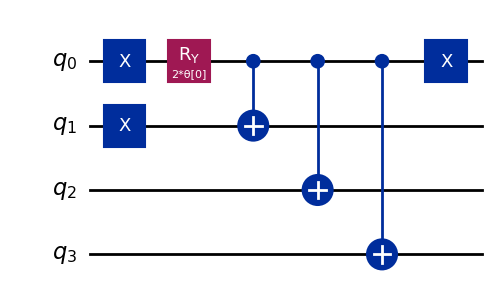

In [17]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

# Define the variational parameters
theta_vector = ParameterVector("θ", 1)

# Build the ansatz
qc = QuantumCircuit(4)

# reference
qc.x(0)
qc.x(1)

qc.ry(2 * theta_vector[0], 0)

qc.cx(0, 1)
qc.cx(0, 2)
qc.cx(0, 3)

qc.x(0)

qc.draw('mpl')


In [18]:
import numpy as np
from scipy.optimize import minimize

# Initial parameters
x0 = np.random.rand(1)

# Optimization
result = minimize(
    cost_function,
    x0,
    args=(H_qubit),
    method="COBYLA",
    options={"maxiter": 200,
             "disp": True,
             "rhobeg": 0.5,
             "tol": 1e-4,
    },
)

print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)

Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 24   Least value of F = -1.1379027888104716
The corresponding X is: [1.46117625]

Optimal parameters: [1.46117625]
Minimum energy: -1.1379027888104716


In [19]:
print('Sz: {:.5f}'.format(cost_function(params=result.x, H_qubit=sz_operator(2))))
print('Energy: {:.5f}'.format(cost_function(params=result.x, H_qubit=H_qubit)))

Sz: -0.00028
Energy: -1.13685


Ansatz Chemical Inspired (UCC)

exact

In [21]:
from scipy.sparse.linalg import expm, expm_multiply

# a b a b a b
state = FermionOperator('0^ 1^')
H_sparse = get_sparse_operator(H_qubit, n_qubits=4)

def cost_function_exact(params):

    sparse_state = get_sparse_operator(state, n_qubits=4)

    T = params[0] * (FermionOperator('3^ 2^ 1 0 ') - FermionOperator('0^ 1^ 2 3')) # must be Hermitian
    t_qubit = jordan_wigner(T)

    for op in t_qubit.get_operators():
        sparse_op = get_sparse_operator(op, n_qubits=4)
        sparse_state = expm_multiply(sparse_op, sparse_state)

    return (sparse_state.T.conj() @ H_sparse @ sparse_state)[0, 0].real


In [22]:
import numpy as np
from scipy.optimize import minimize

# Initial parameters
x0 = np.random.rand(1)

# Optimization
result = minimize(
    cost_function_exact,
    x0,
    method="COBYLA",
    options={"maxiter": 200,
             "disp": True,
             "rhobeg": 0.5,
             "tol": 1e-4,
    },
)

print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)

Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 24   Least value of F = -1.1372838321435152
The corresponding X is: [0.11282088]

Optimal parameters: [0.11282088]
Minimum energy: -1.1372838321435152


Circuit

In [23]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

def get_circuit(params):
    T = params[0] * (FermionOperator('3^ 2^ 1 0 ') - FermionOperator('0^ 1^ 2 3')) # must be Hermitian
    t_qubit = jordan_wigner(T)
    #print(t_qubit)

    # Build the ansatz
    qc = QuantumCircuit(4)

    qc.x(0)
    qc.x(1)

    i_op = 0
    for op, coef in t_qubit.terms.items():

        for qubit, pauli in op:
            if pauli == 'X':
                qc.h(qubit)
            elif pauli == 'Y':
                qc.rx(np.pi / 2, [qubit])

        for qubit, pauli in op[1:]:
            qc.cx(qubit, op[0][0])

        if len(op) > 0:
            qc.rz(coef.imag, op[0][0])

        for qubit, pauli in reversed(op[1:]):
            qc.cx(qubit, op[0][0])

        for qubit, pauli in op:
            if pauli == 'X':
                qc.h(qubit)
            elif pauli == 'Y':
                qc.rx(-np.pi / 2, [qubit])

        qc.barrier()

    #qc.draw('mpl')
    return qc

In [29]:
def cost_function(params, H_qubit):
    energy = 0.0
    for op, coeff in H_qubit.terms.items():

        qc_bound = get_circuit(params)

        qc_meas = qc_bound.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=100000).result()
        counts = result[0].data.meas.get_counts()
        # print(counts)

        shots = sum(counts.values())

        for bitstring, count in counts.items():

            parity = 1

            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

In [30]:
import numpy as np
from scipy.optimize import minimize

# Initial parameters
x0 = np.random.rand(1)

# Optimization
result = minimize(
    cost_function,
    x0,
    args=(H_qubit),
    method="COBYLA",
    options={"maxiter": 200,
             "disp": True,
             "rhobeg": 0.5,
             "tol": 1e-4,
    },
)

print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)

Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 17   Least value of F = -1.1174279740012607
The corresponding X is: [0.18928547]

Optimal parameters: [0.18928547]
Minimum energy: -1.1174279740012607


In [26]:
print('Sz: {:.5f}'.format(cost_function(params=result.x, H_qubit=sz_operator(2))))

Sz: 0.00000
